# DV1583 - Tree Motion User Study Analysis

## Imports, loading and cleaning

In [4]:
# Module imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Plot style
sns.set(style="whitegrid")

In [18]:
# Load CSV

# REPLACE TEST WITH SET A
df_A = pd.read_csv("TreeSetA.csv", encoding="cp1252") # Windows encoding for latin.
df_A["form_id"] = "A" # Tag

df_B = pd.read_csv("TreeSetB.csv", encoding="cp1252")
df_B["form_id"] = "B" # Tag

df_C = pd.read_csv("TreeSetC.csv", encoding="cp1252")
df_C["form_id"] = "C" # Tag

df_D = pd.read_csv("TreeSetD.csv", encoding="cp1252")
df_D["form_id"] = "D" # Tag

df_E = pd.read_csv("TreeSetE.csv", encoding="cp1252")
df_E["form_id"] = "E" # Tag

def clean_dataframe(df):
    df.columns = df.columns.str.strip()

    drop_cols = [
        "Starttid", "Slutförandetid", "E-post", "Namn",
        "I hereby agree to participate in this study voluntarily. I have read the explanation of the study, I understand that my response will be anonymous, and I may withdraw at any time without providing a r",
        "DEMO - Rate how natural the motion of the tree appears to be..The motion of the tree felt..."
    ]
    df = df.drop(columns=drop_cols)

    df = df.rename(columns={
        "What is your gender?": "gender",
        "What is your age group?": "age_group",
        "How familiar are you with video games or other computer-generated visual content (e.g 3D animations, VFX, or other digital graphics)?": "familiarity",
        "Were you in a relatively distraction-free environment during the study?": "distraction_free",
        "Did the videos play smoothly without lag or stuttering?": "video_smooth",
        "Was the visual quality of the videos sufficient for you to judge the motions?": "video_quality"
    })
    
    new_columns = {}

    for col in df.columns:
        col_clean = col.strip()

        match_rating = re.search(r"Clip\s*(\d+).*felt", col_clean, re.IGNORECASE)
        match_text   = re.search(r"Clip\s*(\d+).*What made", col_clean, re.IGNORECASE)

        if match_rating:
            clip_num = match_rating.group(1)
            new_columns[col] = f"clip_{clip_num}_rating"
        elif match_text:
            clip_num = match_text.group(1)
            new_columns[col] = f"clip_{clip_num}_comment"

    df = df.rename(columns=new_columns)

    return df

df_A = clean_dataframe(df_A)
df_B = clean_dataframe(df_B)
df_C = clean_dataframe(df_C)
df_D = clean_dataframe(df_D)
df_E = clean_dataframe(df_E)


In [83]:
# Combine forms
df_all = pd.concat([df_A, df_B, df_C, df_D, df_E], ignore_index=True)

# Melt all data
rating_cols = [col for col in df_all.columns if "_rating" in col]

id_cols = ["Id", "form_id", "gender", "age_group",
    "familiarity", "distraction_free",
    "video_smooth", "video_quality"]

df_long = df_all.melt(id_vars=id_cols, value_vars=rating_cols, var_name="clip", value_name="rating")

df_long["clip_num"] = df_long["clip"].str.extract(r"(\d+)").astype(int)

# Load clip order sheet for mapping answers
mapping_sheets = pd.read_excel("clipMapping.xlsx", sheet_name=None)

mapping_list = []

for sheet_name, df_map in mapping_sheets.items():
    # Form ID based on sheet name
    if "A" in sheet_name:
        form_id = "A"
    elif "B" in sheet_name:
        form_id = "B"
    elif "C" in sheet_name:
        form_id = "C"
    elif "D" in sheet_name:
        form_id = "D"
    elif "E" in sheet_name:
        form_id = "E"
    else:
        continue

    df_map["form_id"] = form_id
    mapping_list.append(df_map)

# Combine sheets
mapping = pd.concat(mapping_list, ignore_index=True)

mapping = mapping.rename(columns={"ClipOrder" : "clip_num"})

# Convert Likert ratings to numbers
likert_map = {
    "Very unnatural": 1,
    "Unnatural": 2,
    "Neutral": 3,
    "Natural": 4,
    "Very natural": 5
}

df_long["rating"] = df_long["rating"].str.strip()
df_long["rating_num"] = df_long["rating"].map(likert_map)

df_long = df_long.merge(mapping, on=["form_id", "clip_num"], how="left")

'''DEBUG CORNER FOR CONTROLLING DATA'''
# df_long.info()
# df_long.head()
# df_long["WindModel"].isna().sum()

# df_long["clip_num"].unique()
# mapping["clip_num"].unique()

#df_long["form_id"].unique()
#mapping["form_id"].unique()

# df_long.groupby("WindModel")["ClipID"].nunique()

'DEBUG CORNER FOR CONTROLLING DATA'

## Statistics

In [85]:
# df_long[["ClipID", "Tree", "WindModel", "Setting"]].drop_duplicates().sort_values("ClipID")
summary =  df_long.groupby("WindModel")["rating_num"].agg(["mean", "median", "std", "count"])
summary

#plt.figure()
#sns.barplot(data=df_long, x="WindModel", y="rating_num", estimator=np.mean)
#plt.title("Mean perceived naturalness per wind model")
#plt.show()

,mean,median,std,count
WindModel,,,,
1,2.537634,2.0,1.198553,279
2,3.369176,4.0,1.230568,279
3,3.598566,4.0,1.071272,279


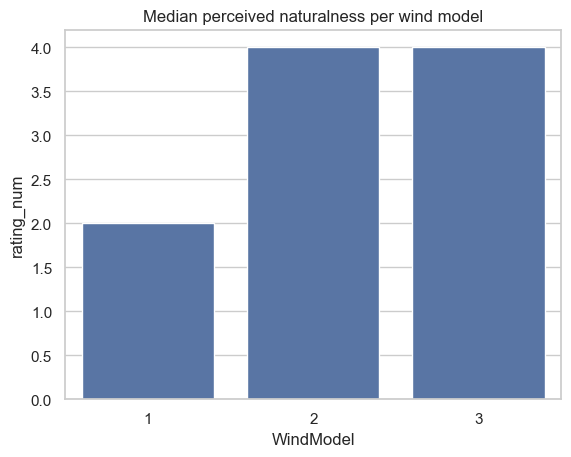

In [86]:
plt.figure()
sns.barplot(data=df_long, x="WindModel", y="rating_num", estimator=np.median, errorbar=None)
plt.title("Median perceived naturalness per wind model")
plt.show()

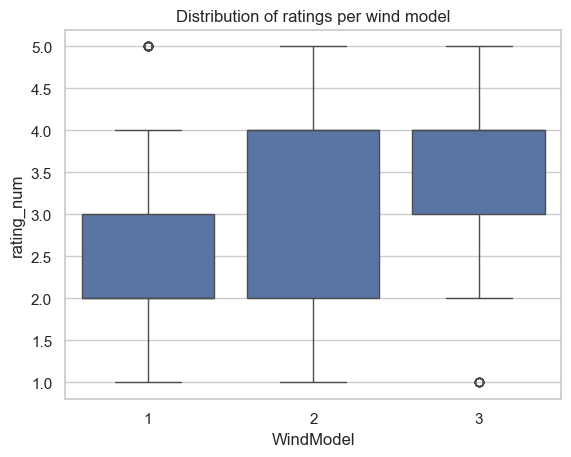

In [84]:
plt.figure()
sns.boxplot(data=df_long, x="WindModel", y="rating_num")
plt.title("Distribution of ratings per wind model")
plt.show()